## Ticket Classification

### Load dataset

 Hugging Face Dataset - https://huggingface.co/datasets/mteb/banking77

In [1]:
# import libraries

from datasets import load_dataset, DatasetDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from transformers import pipeline
from transformers import AutoTokenizer
from transformers import TrainingArguments, Trainer
from transformers import AutoModelForSequenceClassification, DistilBertForSequenceClassification, DistilBertModel

from sklearn.metrics import (
                            classification_report,
                            confusion_matrix,
                            accuracy_score,
                            precision_recall_fscore_support)
# f1_score
from datasets import ClassLabel

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [2]:
# control content display
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)


In [3]:
bank_df = load_dataset("mteb/banking77")
bank_df

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/294k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/91.4k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9993 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3076 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 9993
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 3076
    })
})

In [4]:
test_df = bank_df["test"].to_pandas()
train_df = bank_df["train"].to_pandas()

train_df.head()

,text,label,label_text
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived after 2 weeks?,11,card_arrival
2,I have been waiting over a week. Is the card still coming?,11,card_arrival
3,Can I track my card while it is in the process of delivery?,11,card_arrival
4,"How do I know if I will get my card, or if it is lost?",11,card_arrival


In [5]:
# all the intent categories
label_category = train_df[['label', 'label_text']].drop_duplicates().sort_values('label').reset_index(drop=True)
label_category.head()

,label,label_text
0,0,activate_my_card
1,1,age_limit
2,2,apple_pay_or_google_pay
3,3,atm_support
4,4,automatic_top_up


### Exploratory Analysis

In [6]:
# check duplicate
train_df["text"].duplicated().sum()

np.int64(0)

In [7]:
# data info
train_df["label"].value_counts().describe()

count     77.000000
mean     129.779221
std       32.974321
min       35.000000
25%      111.000000
50%      127.000000
75%      158.000000
max      187.000000
Name: count, dtype: float64

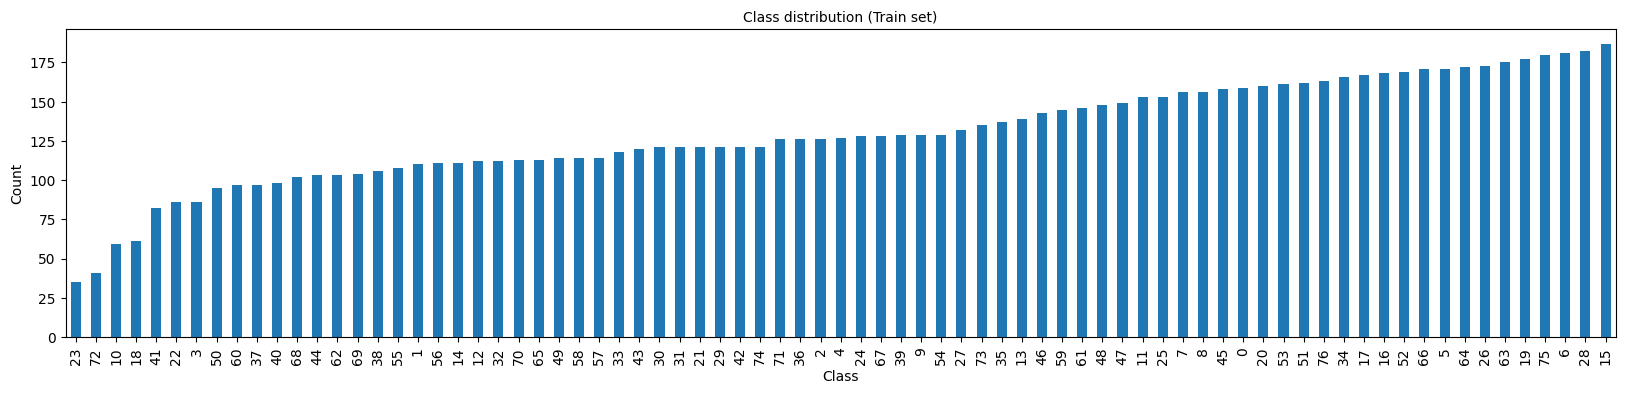

In [8]:
# class distribution - number/count of ticket in each category
train_df["label"].value_counts().sort_values().plot(kind="bar", figsize=(20,4))
plt.title("Class distribution (Train set)", fontsize=10)
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [9]:
# words check
for label in sorted(train_df["label"].unique())[:5]:
    print(f"\nClass {label}")
    print(train_df[train_df["label"] == label]["text"].sample(5).values)


Class 0
['I need to activate my card, how is that done?'
 'Just received my replacement card, what steps do i need to take to activate it?'
 'If you to to account, hit activate, and follow the instructions, you can activate it in just a few seconds.'
 'Is my card ready for use or does it need activated and if so how?'
 "I couldn't complete card activation."]

Class 1
['Do you offer account services for children and teens?'
 'Is there a minimum age for having an account?'
 'Whats the minimum age to have an account'
 'How old must I be to open an account?'
 'What are age requirements for opening an account?']

Class 2
['Can I top up my account with Google Pay?'
 'What are the steps needed to top up with Apple Pay?'
 'How do I top up using my Apple Watch?'
 "Why doesn't my Google pay top up work?"
 'Can I use google play as my primary app to Top up?']

Class 3
['Can this card be used at all ATMs?' 'What cash stations take this card?'
 "Are there specific ATM's that I can draw money from?

In [10]:
# number of words in each text - length analysis
train_df["text_length"] = train_df["text"].apply(lambda x: len(x.split()))
train_df["text_length"].describe()

count    9993.000000
mean       11.955369
std         7.891187
min         3.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        79.000000
Name: text_length, dtype: float64

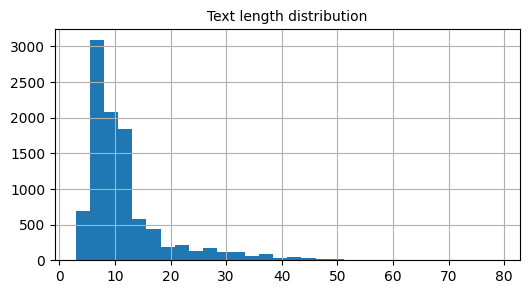

In [11]:
train_df["text_length"].hist(bins=30, figsize=(6,3))
plt.title("Text length distribution", fontsize=10)
plt.show()

In [12]:
# to check worded text, outliers
train_df.sort_values("text_length", ascending=False).head()

,text,label,label_text,text_length
3914,"Hearing back from us regarding your important verification results may take 10 minutes to one hour time. If verification results do fail, double-check to make sure all of your images are clear -- make sure your photos have no glare or blurring. Note: These photos need to be readable as well. You also need to be 18 years of age or older. You must be a resident of Switzerland or the European Economic Area to open a new account.",68,unable_to_verify_identity,79
7301,"Hi! I'm a university student studying abroad and I noticed that when I was trying to cross-reference my budget for this month that there were extra fees I was not expecting. Why is that? I've had this account for years and I haven't had any trouble so far, it might not even be on your all's end since I'm still new to international travel and finance, but I wanted to double check in case a mistake was made!",64,transfer_fee_charged,78
3931,"Hearing about your verification results from us may take anywhere from 10 minutes to approximately one hour. If this verification has in fact, failed, double-check to make sure that your images are clear. Also make sure that your document photos have no blur or glare. They need to be readable. You must also be 18 years of age or older and be a resident of Switzerland or the European Economic Area to open an account.",68,unable_to_verify_identity,75
3902,"You will hear back from us about your verification results in 10 minutes to a one hour timeframe. If these verification results do fail, please double-check to make sure your images are clear and have no glare or blur; your photos need to be fully readable. You need to be 18 years of age or older and a resident of Switzerland or the European Economic Area to create an account.",68,unable_to_verify_identity,70
3907,It can take between 10 minutes to an hour before you hear back from us about the verification result. Please try again if your verification fails. Make sure you double check that images are clear and all document photos are readable without blur or glare. You have to be 18 or older and live in the European Economic area or live in Switzerland to be able to open an account.,68,unable_to_verify_identity,70


In [13]:
# freqently ocurring words counts
words = " ".join(train_df["text"]).lower()
# remove punctuations
all_words = re.findall(r"\b[a-zA-Z']+\b", words)
Counter(all_words).most_common(10)

[('i', 8318),
 ('my', 5682),
 ('to', 4034),
 ('a', 3564),
 ('the', 3497),
 ('card', 2673),
 ('is', 2376),
 ('do', 1848),
 ('it', 1847),
 ('can', 1844)]

#### Most frequest words, excluding stop words

In [14]:
# exclude stop words
filtered_words = [words for words in all_words if words not in ENGLISH_STOP_WORDS]
common_words = Counter(filtered_words).most_common(20)

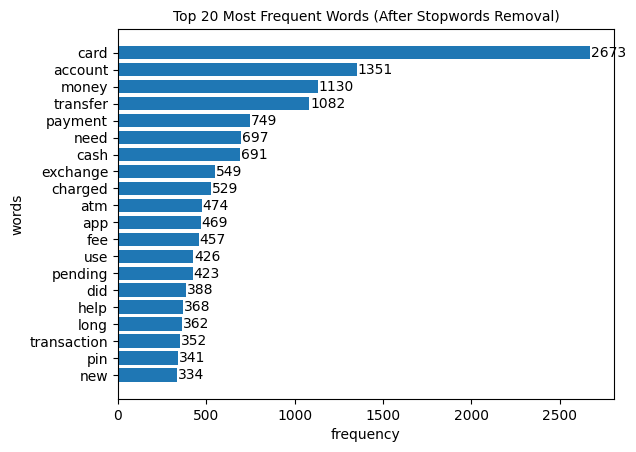

In [15]:
word_df = pd.DataFrame(common_words, columns=["words", "frequency"])
plt.figsize=(12,8)
bars = plt.barh(word_df["words"][::-1], word_df["frequency"][::-1])

for bar in bars:
    plt.text(bar.get_width() +5,
        bar.get_y() + bar.get_height()/2,
        int(bar.get_width()),
        va="center"
)

plt.title("Top 20 Most Frequent Words (After Stopwords Removal)", fontsize=10)
plt.xlabel("frequency")
plt.ylabel("words")
plt.show()

#### TF-IDF vectorisation

In [16]:
# convert features to numeric
vec = TfidfVectorizer(max_features=500)
X = vec.fit_transform(train_df["text"])

#### Principle Component Analysis 

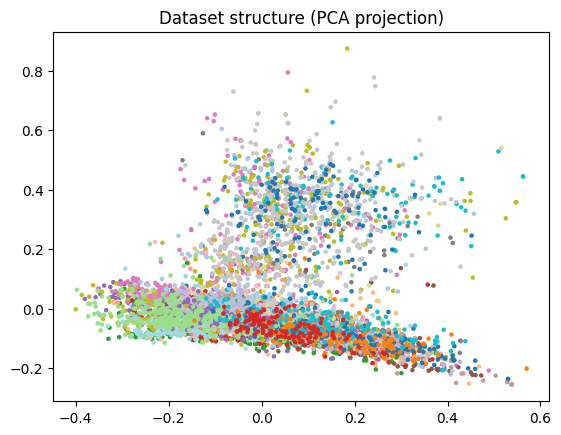

In [17]:
# dimensionality reduction: Principle Component Analaysis
X_reduced = PCA(n_components=2).fit_transform(X.toarray())

plt.scatter(X_reduced[:,0], X_reduced[:,1], c=train_df["label"], cmap="tab20", s=5)
plt.title("Dataset structure (PCA projection)")
plt.show()

### Tokenize the Dataset

In [18]:
# load distilbert tokenizer to convert customers query to numerical tokens
name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [19]:
# test how queries are converted into model inputs with tokenizer
text_sample = "I made a transfer but i did not receive any money"
tokens = tokenizer.tokenize(text_sample)
print(tokens)
print("\n")
display(tokenizer(text_sample))

['i', 'made', 'a', 'transfer', 'but', 'i', 'did', 'not', 'receive', 'any', 'money']




{'input_ids': [101, 1045, 2081, 1037, 4651, 2021, 1045, 2106, 2025, 4374, 2151, 2769, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [20]:
# determine max_length 
token_lengths = [
    len(tokenizer(text, truncation=False)["input_ids"])
    for text in bank_df["train"]["text"]
]

pd.Series(token_lengths).describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

count    9993.000000
mean       16.220955
std         9.217949
min         5.000000
25%        11.000000
50%        13.000000
75%        17.000000
90%        28.000000
95%        37.000000
99%        53.000000
max        98.000000
dtype: float64

In [21]:
for length in [32, 48, 64, 96, 128]:
    truncated = sum(x > length for x in token_lengths)

    print(
        f"Max length {length}: "
        f"{truncated} queries "
        f"({truncated / len(token_lengths) * 100:.2f}%) truncated"
    ) 

Max length 32: 701 queries (7.01%) truncated
Max length 48: 147 queries (1.47%) truncated
Max length 64: 30 queries (0.30%) truncated
Max length 96: 1 queries (0.01%) truncated
Max length 128: 0 queries (0.00%) truncated


In [22]:
# Prepare the dataset(train and test) - this tokenizes the dataset in batches of 16 examples.
bank_tokenized = bank_df.map(
                              lambda example: tokenizer(
                              example['text'], 
                              padding=True, 
                              truncation=True, 
                              max_length=64
                              ), 
                              batched=True, 
                              batch_size=16)

Map:   0%|          | 0/9993 [00:00<?, ? examples/s]

Map:   0%|          | 0/3076 [00:00<?, ? examples/s]

In [23]:
# remove redundant column and rename
bank_tokenized = bank_tokenized.remove_columns(["text", "label_text"])
bank_tokenized = bank_tokenized.rename_column("label", "labels")

# convert dataset numerical features to pytorch format
bank_tokenized.set_format("torch")

In [24]:
print(bank_tokenized)

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9993
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3076
    })
})


In [25]:
bank_tokenized['train'][0:2]

{'labels': tensor([11, 11]),
 'input_ids': tensor([[ 101, 1045, 2572, 2145, 3403, 2006, 2026, 4003, 1029,  102,    0,    0,
             0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0],
         [ 101, 2054, 2064, 1045, 2079, 2065, 2026, 4003, 2145, 8440, 1005, 1056,
          3369, 2044, 1016, 3134, 1029,  102,    0,    0,    0,    0,    0]]),
 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]),
 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]])}

### Split Dataset into Train and Validation Split

In [26]:
# convert label columns into class label before splitting
bank_tokenized = bank_tokenized.cast_column(
    "labels",
    ClassLabel(num_classes=77)
)

Casting the dataset:   0%|          | 0/9993 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/3076 [00:00<?, ? examples/s]

In [27]:
# split train dataset into train and validation set

split = bank_tokenized['train'].train_test_split(test_size=0.2, 
                                                 seed=224,
                                                 stratify_by_column="labels")

bank_tokenized = bank_tokenized.cast_column(
    "labels",
    ClassLabel(num_classes=77)
)

train_dataset = split['train']   # 80% of original train
val_dataset = split['test']      # 20% of original train 

# original test dataset
test_dataset = bank_tokenized['test']

print("training:", len(train_dataset))
print("testing:", len(val_dataset))
print("validating:", len(test_dataset))

Casting the dataset:   0%|          | 0/9993 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/3076 [00:00<?, ? examples/s]

training: 7994
testing: 1999
validating: 3076


### Fine-tune with HuggingFace Trainer
Load predefined DistilBert classification model

In [28]:
model = DistilBertForSequenceClassification.from_pretrained(
                                                        'distilbert-base-uncased', 
                                                         num_labels=77)

# configure training arguement
arguments = TrainingArguments(
    output_dir="banking77_trainer",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=8,
    eval_strategy="epoch", # run validation at the end of each epoch
    save_strategy="epoch",
    weight_decay=0.01,
    learning_rate=2e-5,
    load_best_model_at_end=True,
    seed=224
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Define evaluation metrics

In [29]:
def compute_metrics(eval_pred):
    """Called at the end of validation. Gives accuracy"""
    logits, labels = eval_pred

    # convert model output to predicted class label
    predictions = np.argmax(logits, axis=-1)
    
    # calculates the accuracy
    # acc = np.mean(predictions == labels)
    acc = accuracy_score(labels, predictions)

    # calculate precioin, recall and f1-score
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )
    
    return {"accuracy": acc, 
            "f1_macro": f1, 
            "precision": precision, 
            "recall": recall}


In [30]:
# initialise the trainer
trainer = Trainer(
    model=model,
    args=arguments,
    train_dataset=train_dataset,
    eval_dataset=val_dataset, 
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

In [31]:
# train the model
trainer.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Precision,Recall
1,No log,5.596464,0.590295,0.531509,0.645049,0.556231
2,5.975225,3.308438,0.755878,0.701648,0.753598,0.717477
3,5.975225,2.079175,0.821911,0.797143,0.837419,0.798703
4,2.244539,1.467244,0.869935,0.854267,0.868329,0.855478
5,2.244539,1.183337,0.877939,0.864192,0.875028,0.864597
6,1.057322,1.038132,0.888444,0.875807,0.882662,0.875997
7,1.057322,0.969933,0.890945,0.879205,0.885054,0.879781
8,0.708059,0.944329,0.889445,0.880063,0.895527,0.878931


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (9 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


TrainOutput(global_step=2000, training_loss=2.4962863159179687, metrics={'train_runtime': 316.1792, 'train_samples_per_second': 202.265, 'train_steps_per_second': 6.326, 'total_flos': 1036236010283904.0, 'train_loss': 2.4962863159179687, 'epoch': 8.0})

In [32]:
# evaluate test dataset
test_results = trainer.evaluate(eval_dataset=test_dataset)
print(test_results)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 0.930709958076477, 'eval_accuracy': 0.8988946684005201, 'eval_f1_macro': 0.8973225770162487, 'eval_precision': 0.9072909031359829, 'eval_recall': 0.8989094239094239, 'eval_runtime': 4.2985, 'eval_samples_per_second': 715.598, 'eval_steps_per_second': 22.566, 'epoch': 8.0}


In [33]:
# generate test prediction
predictions = trainer.predict(test_dataset)

# extract predicted class labels
y_pred = predictions.predictions.argmax(axis=1)

# extract actual class labels
y_true = predictions.label_ids

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


In [34]:
# created mapping between labels and intent name
label_mapping = label_category.set_index("label")["label_text"].to_dict()

label_names = [label_mapping[i] for i in range(77)]
print(label_names)

['activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up', 'balance_not_updated_after_bank_transfer', 'balance_not_updated_after_cheque_or_cash_deposit', 'beneficiary_not_allowed', 'cancel_transfer', 'card_about_to_expire', 'card_acceptance', 'card_arrival', 'card_delivery_estimate', 'card_linking', 'card_not_working', 'card_payment_fee_charged', 'card_payment_not_recognised', 'card_payment_wrong_exchange_rate', 'card_swallowed', 'cash_withdrawal_charge', 'cash_withdrawal_not_recognised', 'change_pin', 'compromised_card', 'contactless_not_working', 'country_support', 'declined_card_payment', 'declined_cash_withdrawal', 'declined_transfer', 'direct_debit_payment_not_recognised', 'disposable_card_limits', 'edit_personal_details', 'exchange_charge', 'exchange_rate', 'exchange_via_app', 'extra_charge_on_statement', 'failed_transfer', 'fiat_currency_support', 'get_disposable_virtual_card', 'get_physical_card', 'getting_spare_card', 'getting_virtual_card'

In [35]:
# generate classification report
report = classification_report(y_true, 
                               y_pred, 
                              labels=list(range(77)),
                              target_names=label_names,
                              zero_division=0)
                              # digits=2)
print(report)

                                                  precision    recall  f1-score   support

                                activate_my_card       1.00      0.95      0.97        40
                                       age_limit       1.00      1.00      1.00        40
                         apple_pay_or_google_pay       1.00      1.00      1.00        40
                                     atm_support       1.00      0.97      0.99        39
                                automatic_top_up       0.97      0.93      0.95        40
         balance_not_updated_after_bank_transfer       0.74      0.80      0.77        40
balance_not_updated_after_cheque_or_cash_deposit       0.97      0.97      0.97        40
                         beneficiary_not_allowed       0.93      0.93      0.93        40
                                 cancel_transfer       0.97      0.90      0.94        40
                            card_about_to_expire       0.93      1.00      0.96        40
         

In [36]:
# confusion matrix
c_matrix = confusion_matrix(y_true, y_pred)

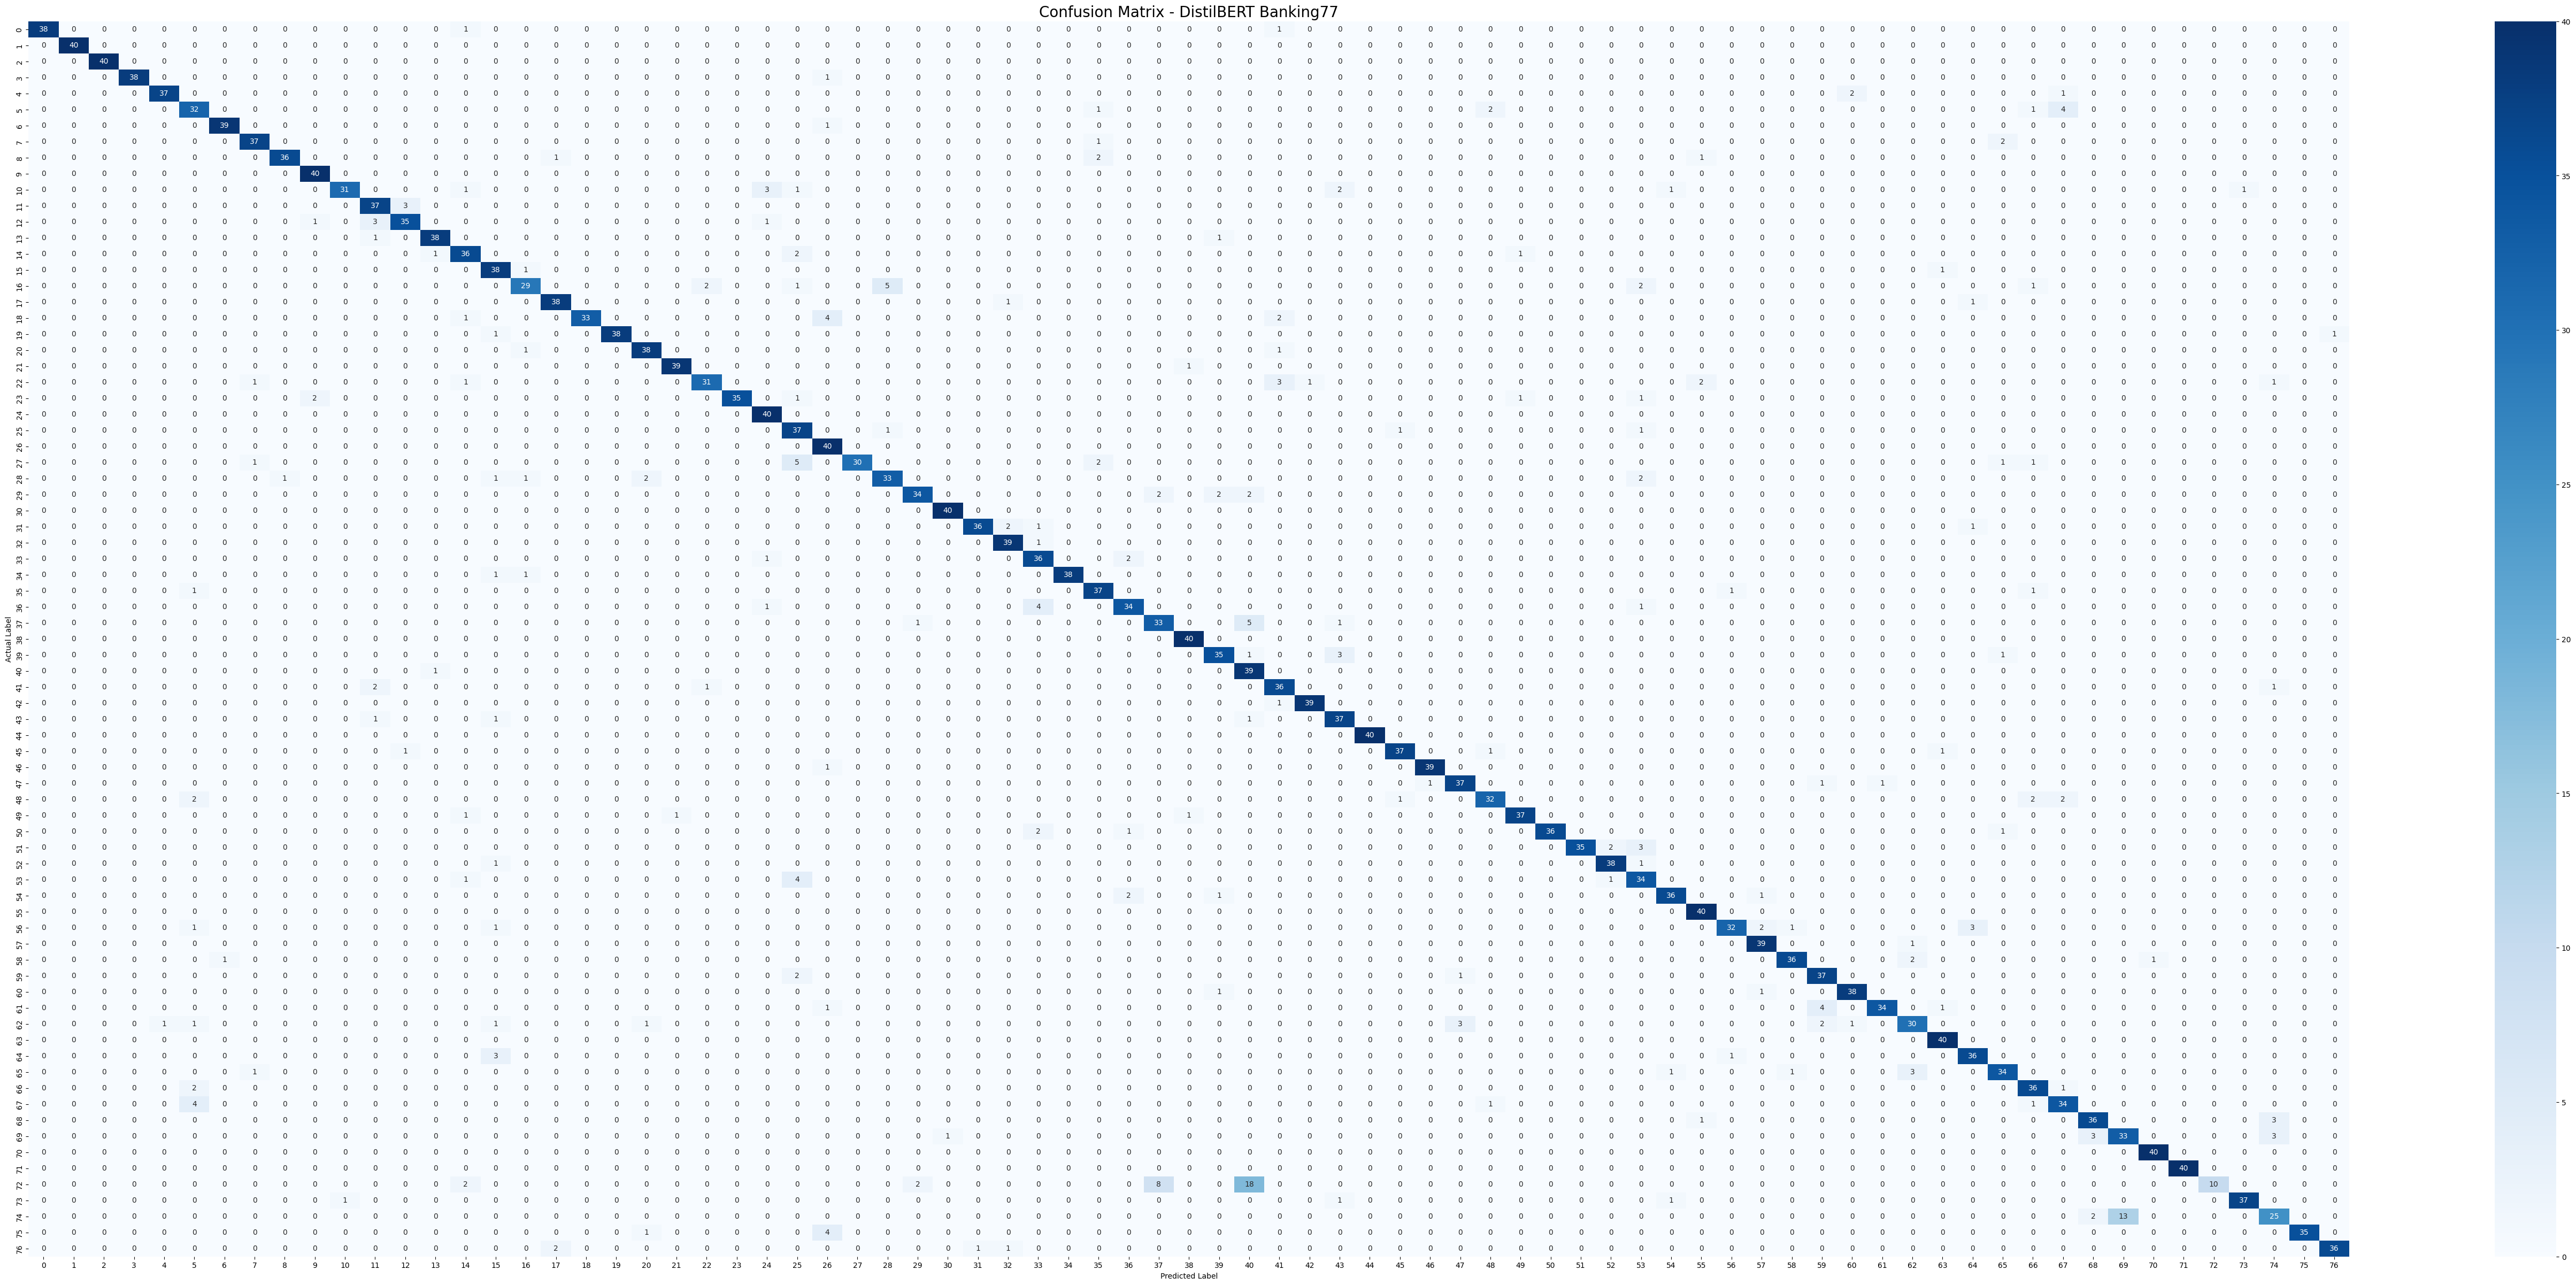

In [37]:
plt.figure(figsize=(70,30))

sns.heatmap(
    c_matrix,
    annot=True,
    cmap="Blues"
    # fmt=".2f"
)

plt.title("Confusion Matrix - DistilBERT Banking77", fontsize=20)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [38]:
# save the train model
trainer.save_model("./banking77_distilbert")
tokenizer.save_pretrained("./banking77_distilbert")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./banking77_distilbert/tokenizer_config.json',
 './banking77_distilbert/tokenizer.json')

### Error Analysis

In [39]:
# original test data
test_text = bank_df["test"]["text"]

error_df = pd.DataFrame({"text": test_text,
                        "actual_label": y_true, 
                        "predicted_label":y_pred})

# retrievce only misclassified examples
error_df = error_df[error_df["actual_label"] != error_df["predicted_label"]].copy()
print("Total test examples:", len(y_true))
print("Misclassified examples:", len(error_df))

error_rate = len(error_df) / len(y_true) * 100
print(f"Misclassification rate: {error_rate:.2f}%")


Total test examples: 3076
Misclassified examples: 311
Misclassification rate: 10.11%


In [40]:
# convert numerical labelsinto intent names
error_df["actual_intent"] = error_df["actual_label"].map(label_mapping)
error_df["predicted_intent"] = error_df["predicted_label"].map(label_mapping)
error = error_df[["text", "actual_intent", "predicted_intent"]].reset_index(drop=True)

In [41]:
# most frequent classification mistake
error_pattern = (error.groupby(["actual_intent", "predicted_intent"]).size()
                 .reset_index(name="error_count")
                 .sort_values("error_count", ascending=False)
                .reset_index(drop=True))
error_pattern

,actual_intent,predicted_intent,error_count
0,virtual_card_not_working,getting_virtual_card,18
1,why_verify_identity,verify_my_identity,13
2,virtual_card_not_working,get_disposable_virtual_card,8
3,declined_transfer,declined_card_payment,5
4,card_payment_not_recognised,direct_debit_payment_not_recognised,5
5,get_disposable_virtual_card,getting_virtual_card,5
6,transfer_timing,balance_not_updated_after_bank_transfer,4
7,reverted_card_payment?,declined_card_payment,4
8,fiat_currency_support,exchange_via_app,4
9,card_swallowed,declined_cash_withdrawal,4
